# Task 4 — QAOA Depth Experiment (p = 1, 2, 3, 4)

**Goal:** measure how the QAOA approximation ratio changes with circuit depth, using the exact formula from the hackathon challenge:

\[
r=\frac{C_{\max}-\langle C\rangle}{C_{\max}-C_{\min}},
\]

where \(C_{\max}\) and \(C_{\min}\) are computed over all \(2^n=64\) bitstrings for the same penalty strength \(\lambda\).

This notebook is self-contained and uses a local statevector simulator. Results can vary with optimizer settings, so interpret the plot as experimental evidence rather than a guarantee that deeper circuits always perform better.

## 1. Imports and fixed challenge data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector

rng = np.random.default_rng(2026)
n, K, q = 6, 3, 0.5
lam = 1.0
mu = rng.uniform(0.05, 0.25, n)
A = rng.normal(0, 0.1, (n, n))
sigma = A @ A.T

def portfolio_cost(x, lam=lam):
    x = np.asarray(x, dtype=int)
    return float(q * (x @ sigma @ x) - mu @ x + lam * (x.sum() - K) ** 2)

print("Stocks:", n, "| choose:", K, "| lambda:", lam)

Stocks: 6 | choose: 3 | lambda: 1.0


## 2. Build the cost Hamiltonian and compute C_min/C_max over all bitstrings

In [2]:
def build_cost_hamiltonian(lam):
    a = q * np.diag(sigma) - mu + lam * (1 - 2 * K)
    b = {(i, j): 2 * q * sigma[i, j] + 2 * lam
         for i in range(n) for j in range(i + 1, n)}
    terms = {}
    def add(label, coeff):
        terms[label] = terms.get(label, 0.0) + float(coeff)

    identity = "I" * n
    add(identity, lam * K**2)
    for i in range(n):
        label = ["I"] * n
        label[n - 1 - i] = "Z"
        add(identity, a[i] / 2)
        add("".join(label), -a[i] / 2)
    for (i, j), coeff in b.items():
        add(identity, coeff / 4)
        li = ["I"] * n
        li[n - 1 - i] = "Z"
        add("".join(li), -coeff / 4)
        lj = ["I"] * n
        lj[n - 1 - j] = "Z"
        add("".join(lj), -coeff / 4)
        lij = ["I"] * n
        lij[n - 1 - i] = "Z"
        lij[n - 1 - j] = "Z"
        add("".join(lij), coeff / 4)

    return SparsePauliOp.from_list(
        [(label, coeff) for label, coeff in terms.items() if abs(coeff) > 1e-12]
    ).simplify()

all_x = [np.array(bits, dtype=int) for bits in product([0, 1], repeat=n)]
all_costs = np.array([portfolio_cost(x, lam) for x in all_x])
C_min = float(all_costs.min())
C_max = float(all_costs.max())
cost_hamiltonian = build_cost_hamiltonian(lam)

print("All bitstrings:", len(all_x))
print("C_min:", round(C_min, 6))
print("C_max:", round(C_max, 6))

All bitstrings: 64
C_min: -0.503015
C_max: 9.0


## 3. QAOA circuit and expectation value

The circuit applies cost unitaries from the `Z` and `ZZ` terms, followed by the standard `RX` mixer. The identity term is omitted from the circuit because it contributes only a global phase, but the full Hamiltonian is used when calculating the expectation value.

In [3]:
pauli_coeffs = {
    label: float(np.real(coeff))
    for label, coeff in zip(cost_hamiltonian.paulis.to_labels(), cost_hamiltonian.coeffs)
}

def qaoa_state(params, p):
    gammas = params[:p]
    betas = params[p:]
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for layer in range(p):
        gamma, beta = gammas[layer], betas[layer]
        for label, coeff in pauli_coeffs.items():
            z_positions = [pos for pos, char in enumerate(label) if char == "Z"]
            if len(z_positions) == 1:
                qc.rz(2 * gamma * coeff, n - 1 - z_positions[0])
            elif len(z_positions) == 2:
                qa, qb = n - 1 - z_positions[0], n - 1 - z_positions[1]
                qc.rzz(2 * gamma * coeff, qa, qb)
        for qubit in range(n):
            qc.rx(2 * beta, qubit)
    return Statevector.from_instruction(qc)

def expected_cost(params, p):
    return float(np.real(qaoa_state(params, p).expectation_value(cost_hamiltonian)))

print("QAOA circuit helpers ready.")

QAOA circuit helpers ready.


## 4. Optimize QAOA at depths p = 1, 2, 3, 4

We use multiple random initializations per depth and keep the run with the lowest expected cost. Increase `restarts` or `maxiter` if you have time; more optimization can improve results but takes longer.

In [4]:
restarts = 3
maxiter = 180
depth_results = []
rng_opt = np.random.default_rng(2401)

for p in range(1, 5):
    best_result = None
    for restart in range(restarts):
        x0 = np.concatenate([
            rng_opt.uniform(0, np.pi, p),
            rng_opt.uniform(0, np.pi / 2, p),
        ])
        result = minimize(
            fun=lambda params, depth=p: expected_cost(params, depth),
            x0=x0,
            method="COBYLA",
            options={"maxiter": maxiter, "rhobeg": 0.5},
        )
        if best_result is None or result.fun < best_result.fun:
            best_result = result

    expectation = float(best_result.fun)
    ratio = (C_max - expectation) / (C_max - C_min)
    depth_results.append({
        "p": p,
        "expected_cost": expectation,
        "approximation_ratio": ratio,
        "optimizer_success": bool(best_result.success),
        "nfev": int(best_result.nfev),
        "params": best_result.x,
    })
    print(
        f'p={p} | <C>={expectation:.6f} | '
        f'approximation ratio={ratio:.6f} | '
        f'evaluations={best_result.nfev}'
    )

p=1 | <C>=0.110714 | approximation ratio=0.935418 | evaluations=38
p=2 | <C>=-0.320226 | approximation ratio=0.980765 | evaluations=180
p=3 | <C>=-0.055274 | approximation ratio=0.952884 | evaluations=180
p=4 | <C>=-0.056589 | approximation ratio=0.953023 | evaluations=180


## 5. Plot approximation ratio against circuit depth

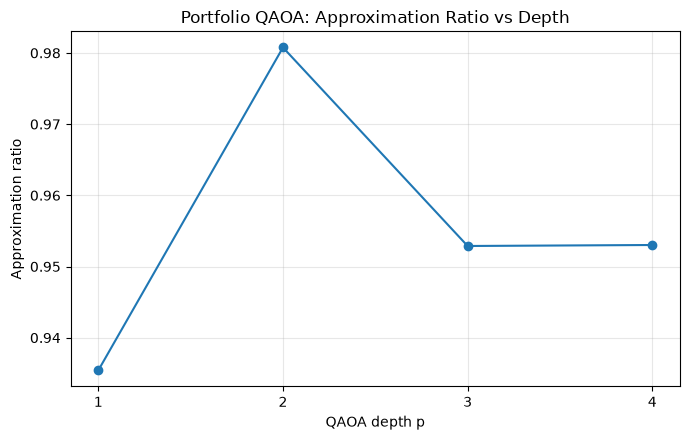

In [5]:
depths = [row["p"] for row in depth_results]
ratios = [row["approximation_ratio"] for row in depth_results]

plt.figure(figsize=(7, 4.5))
plt.plot(depths, ratios, marker="o")
plt.xticks(depths)
plt.xlabel("QAOA depth p")
plt.ylabel("Approximation ratio")
plt.title("Portfolio QAOA: Approximation Ratio vs Depth")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Interpret the experiment

- Compare the ratios for p=1 through p=4.
- A higher ratio is better under the challenge's specified formula.
- The ratios may not increase monotonically because optimization is non-convex and we use a limited number of restarts.
- Report the number of restarts and iteration limit in your project so the experiment is reproducible.
- Do not compare ratios computed with different penalty strengths unless you also recompute \(C_{\min}\) and \(C_{\max}\) for each strength.

## Task 4 completion checklist

- [ ] Notebook runs from top to bottom.
- [ ] It prints results for p=1, 2, 3, 4.
- [ ] It displays the approximation-ratio plot.
- [ ] Record the values from your own run for the report.

**Stop after this notebook runs successfully.** Task 5 will separately study penalty strength \(\lambda\) and the fraction of samples that select exactly K=3 stocks.